In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import sqlite3
from sklearn.metrics.pairwise import pairwise_distances
import matplotlib.pyplot as plt
import math

In [2]:
con = sqlite3.connect(database="data.sqlite")


data = pd.read_sql_query(
  sql="SELECT * FROM cleaned_data",
  con=con,
  parse_dates={"Period"}
)
con.close()

In [3]:
# Our out-of-sample period starts from Jan 2017 to March 2026. This allows us to see how the model performs during the stability of 2010s,
# COVID recession and Post-COVID inflationary environment. Also, US weather disasters have become more common in the past decade, allowing
# us to see the impact on mortgages.

# Due to how our default variable is defined, we want a 1 year buffer between training and test set.
# Hence, our training set for model performance starts in Jan 2012 and ends in Dec 2015

# We will conduct our data exploration on data up to Dec 2011


train = data.loc[data["Period"] <= "2011-12-01",:]



Axes(0.125,0.11;0.62x0.77)


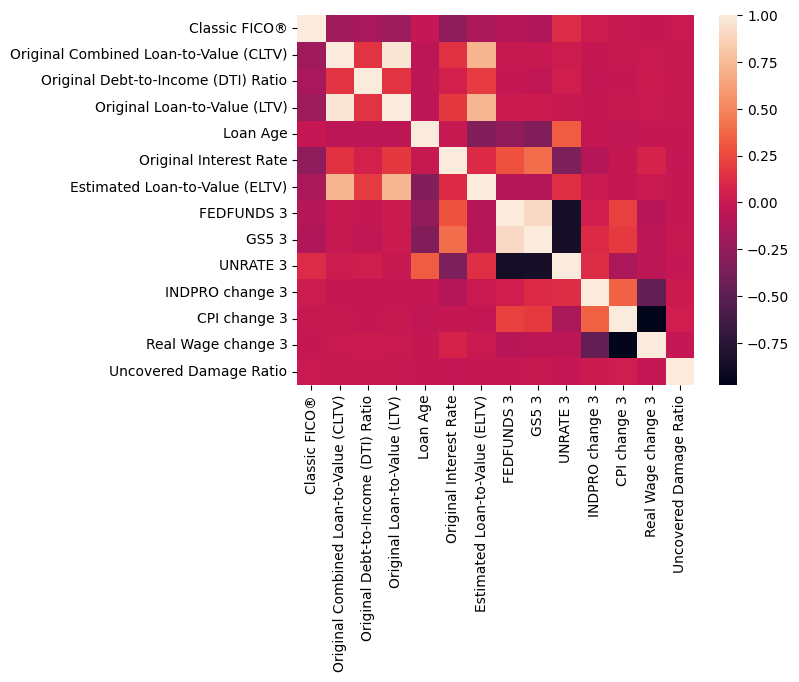

In [4]:
# DATA EXPLORATION:
# We will examine multicollinearity of numeric columns
numeric_cols = ["Classic FICO®","Original Combined Loan-to-Value (CLTV)","Original Debt-to-Income (DTI) Ratio","Original Loan-to-Value (LTV)",
                "Loan Age","Original Interest Rate","Estimated Loan-to-Value (ELTV)","FEDFUNDS 3","GS5 3","UNRATE 3","INDPRO change 3",
                "CPI change 3","Real Wage change 3","Uncovered Damage Ratio"]

corr = train.loc[:,numeric_cols].corr()
print(sns.heatmap(corr))

In [5]:
# We examine the particular values of high correlations in more detail
print(train.loc[:,["Original Combined Loan-to-Value (CLTV)","Estimated Loan-to-Value (ELTV)","Original Loan-to-Value (LTV)"]].corr())

print(train.loc[:,["FEDFUNDS 3","GS5 3","UNRATE 3"]].corr())

print(train.loc[:,["CPI change 3","Real Wage change 3"]].corr())



# Will remove LTV as it has extremely high correlation with CLTV and greater correlation than CLTV with ELTV
# Additionally, CLTV includes client debts beyond the mortgage when available which may be more informative for default prediction
# Will remove Real Wage as it has extremely high correlation with CPI and is completely filled with missing values prior to 2006
# Although correlation between fed funds rate and 5-year rate is high, they are proxies for different borrowing costs so I keep them
train = train.loc[:,~train.columns.isin(["Real Wage change 3","Real Wage change 6","Real Wage change 9","Original Loan-to-Value (LTV)"])]



                                        Original Combined Loan-to-Value (CLTV)  \
Original Combined Loan-to-Value (CLTV)                                1.000000   
Estimated Loan-to-Value (ELTV)                                        0.716489   
Original Loan-to-Value (LTV)                                          0.965694   

                                        Estimated Loan-to-Value (ELTV)  \
Original Combined Loan-to-Value (CLTV)                        0.716489   
Estimated Loan-to-Value (ELTV)                                1.000000   
Original Loan-to-Value (LTV)                                  0.728890   

                                        Original Loan-to-Value (LTV)  
Original Combined Loan-to-Value (CLTV)                      0.965694  
Estimated Loan-to-Value (ELTV)                              0.728890  
Original Loan-to-Value (LTV)                                1.000000  
            FEDFUNDS 3     GS5 3  UNRATE 3
FEDFUNDS 3    1.000000  0.903133 -0.867519
GS5 

In [6]:
# For binary columns, we use the Jaccard similarity measure as most binary values for each column are 0
# Note that by definition, Moderate and Extreme Disasters do not overlap
binary_cols = ["First Time Homebuyer Indicator","HARP Indicator","Moderate Disaster","Extreme Disaster",
               "Primary Residence"]

# Low similarity between all binary variables
print(np.round(1 - pairwise_distances(train.loc[:,binary_cols].T.to_numpy(), metric='jaccard'),3))





c:\Users\arnur\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


[[1.    0.    0.018 0.004 0.091]
 [0.    1.    0.011 0.006 0.021]
 [0.018 0.011 1.    0.    0.021]
 [0.004 0.006 0.    1.    0.005]
 [0.091 0.021 0.021 0.005 1.   ]]


c:\Users\arnur\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


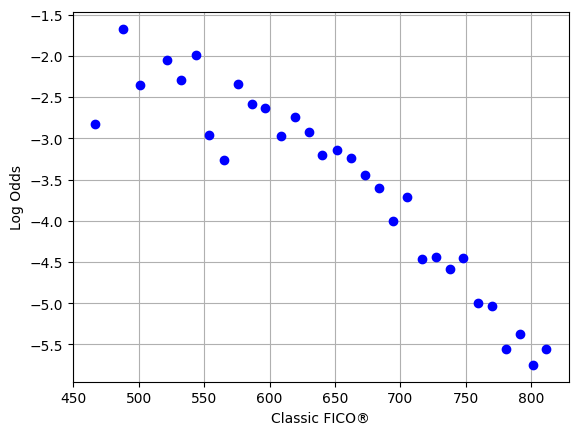

c:\Users\arnur\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


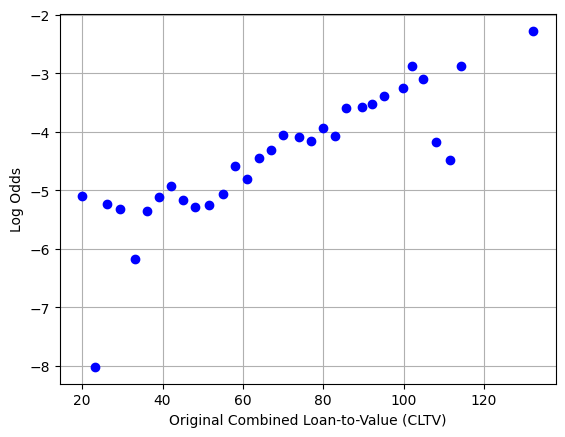

c:\Users\arnur\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


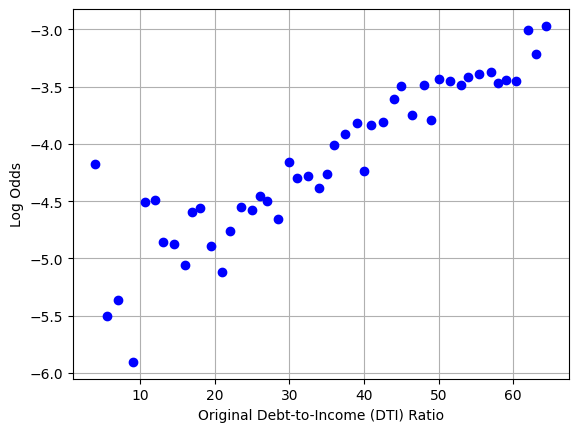

c:\Users\arnur\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


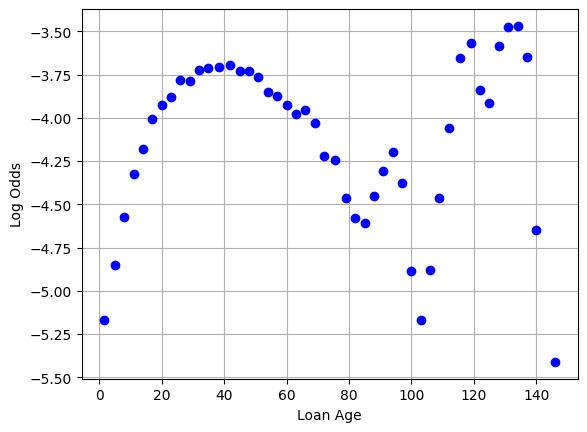

c:\Users\arnur\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


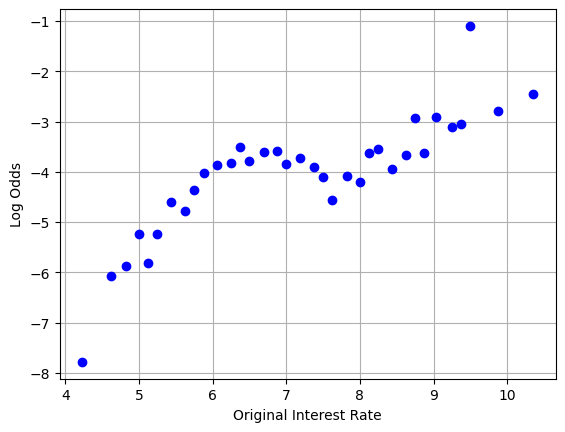

c:\Users\arnur\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


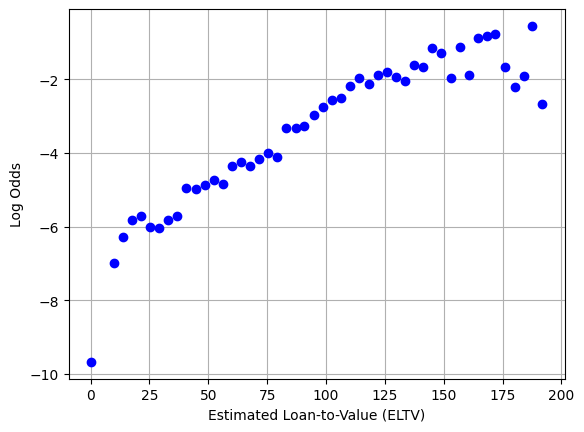

c:\Users\arnur\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


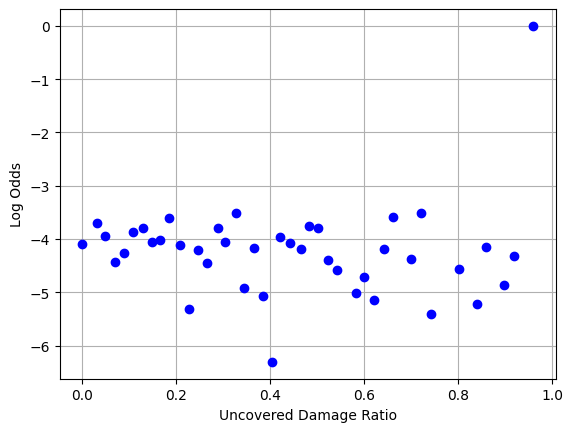

In [7]:
# Feature Transformation
# Aoart from logit regression, we will also use gradient boosting
# Since strictly monotonic transformations shouldn't affect tree-based algorithms, we will focus on data transformations for logit
# We will check log-odds linearity using binning and graphs
def log_odds_plot(df,x_var,bins=50,sensitivity_values=[],bin_list=[]):
    df["bins"] = pd.cut(df[x_var],bins)
    
    # Note that many bins do not have any observations, which are excluded
    log_odds = (df.groupby("bins",observed=True).agg(default_sum =("Default Next 12","sum"),
                                       default_count = ("Default Next 12","count"),
                                       average_x = (x_var,"mean")))
    
    # Some bins don't have defaults so we also exclude them
    log_odds["log odds"] = (np.log(log_odds["default_sum"]/log_odds["default_count"]) 
                            - np.log(1 - (log_odds["default_sum"]/log_odds["default_count"])))
    log_odds["log odds"] = log_odds["log odds"].replace([np.inf, -np.inf], np.nan)
    log_odds.dropna(inplace=True)
    
    plt.plot(log_odds["average_x"],log_odds["log odds"],color="blue", marker="o",linestyle="None")
    plt.xlabel(x_var)
    plt.ylabel("Log Odds")
    plt.grid(True)
    if sensitivity_values:  
        for bin in bin_list:
            x_series = [log_odds.iloc[bin,:]["average_x"]] * len(sensitivity_values)
            y_series = []
            for value in sensitivity_values:
                # Bins with 0 defaults are not allowed as then they would be excluded
                adjusted_default_sum = max((log_odds.iloc[bin,:]["default_sum"] + value),1)
                default_count = log_odds.iloc[bin,:]["default_count"]
                adjusted_log_odds = math.log(adjusted_default_sum/default_count) - math.log(1 - (adjusted_default_sum/default_count))
                y_series.append(adjusted_log_odds)

            plt.scatter(x_series,y_series,color="red",marker="o")
        

    plt.show()


numeric_cols = ["Classic FICO®","Original Combined Loan-to-Value (CLTV)","Original Debt-to-Income (DTI) Ratio",
                  "Loan Age","Original Interest Rate","Estimated Loan-to-Value (ELTV)","Uncovered Damage Ratio"]

# The sign of the relationships (i.e. as Classic FICO increases, default chance decrease so log odds decreases) generally hold
# except for Uncovered Damage Ratio
for x in numeric_cols:
    log_odds_plot(train,x)

c:\Users\arnur\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


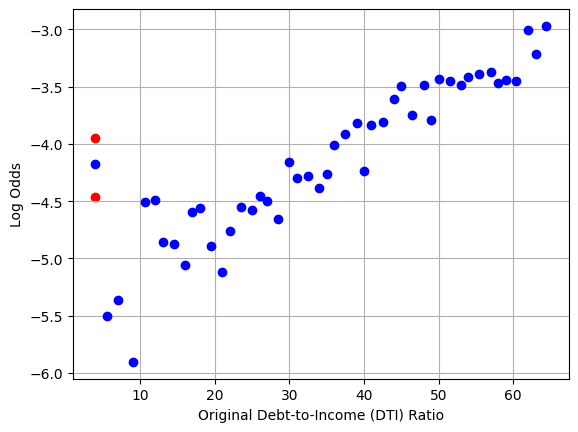

c:\Users\arnur\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


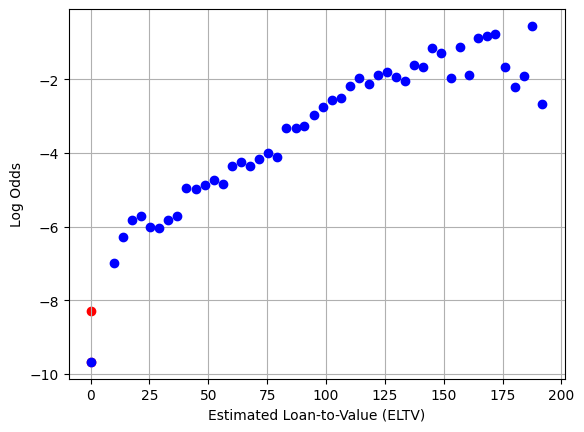

c:\Users\arnur\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


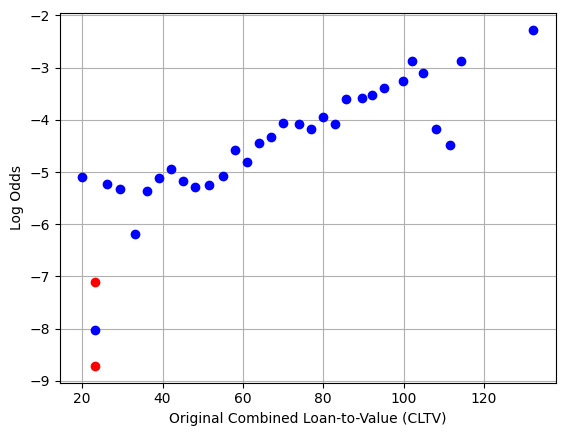

c:\Users\arnur\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


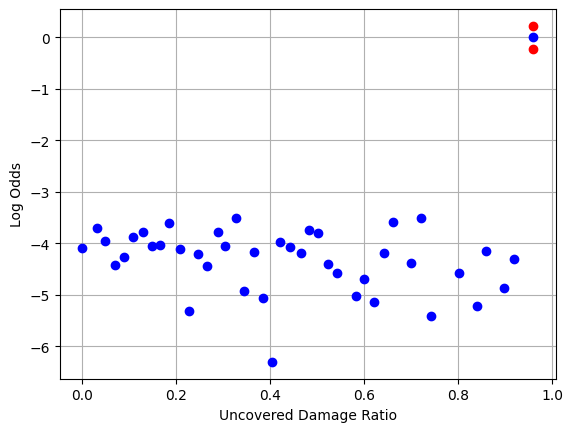

c:\Users\arnur\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


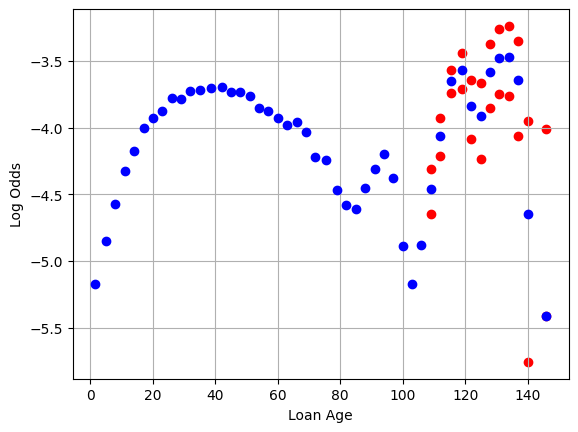

Last bin proportion of Extreme Disasters
1.0


In [8]:
# Some bins have very few defaults, so small-sample variance could explain outlier log-odds results
# Hence we conduct a sensitivity analysis to see if those outlier results become more in line if a few defaults are added or subtracted

# The sensitivity analysis shows that small-sample variance is responsible for most of these outliers as their log odds value changes
# drastically
log_odds_plot(train,"Original Debt-to-Income (DTI) Ratio",sensitivity_values=[-3,3],bin_list=[0])

log_odds_plot(train,"Estimated Loan-to-Value (ELTV)",sensitivity_values=[-3,3],bin_list=[0])

log_odds_plot(train,"Original Combined Loan-to-Value (CLTV)",sensitivity_values=[-3,3],bin_list=[1])

log_odds_plot(train,"Uncovered Damage Ratio",sensitivity_values=[-3,3],bin_list=[41])

log_odds_plot(train,"Loan Age",sensitivity_values=[-3,3],bin_list=range(35,47))

# The last bin for Uncovered Damage Ratio cannot be attributed to small-sample variance so we examine it in more detail
# We find that the observations in that bin coincide completely with extreme disasters
# Hence we leave this outlier as it may be explained by the Extreme Disaster variable 
print("Last bin proportion of Extreme Disasters")
print(train.loc[(train["Uncovered Damage Ratio"] <= 0.972) & (train["Uncovered Damage Ratio"] > 0.952),:]["Extreme Disaster"].mean())

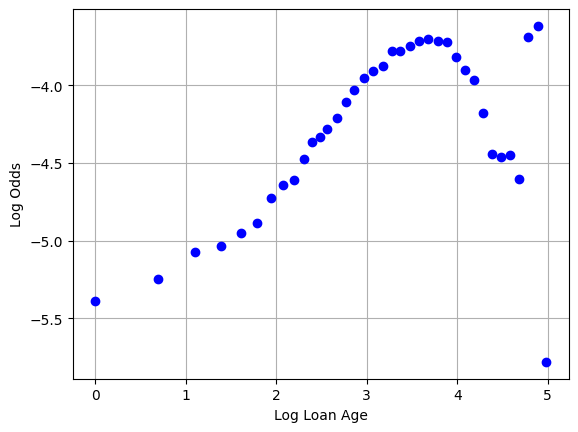

In [9]:
# Additionally, we see that Loan Age has a nonlinear relationship with log odds, with the first section looking more logarithmic, before
# linearly decreasing
# Hence, we create a logarithm variable as well
train["Log Loan Age"] = train["Loan Age"].apply(lambda x: math.log(1 + x))
log_odds_plot(train,"Log Loan Age")

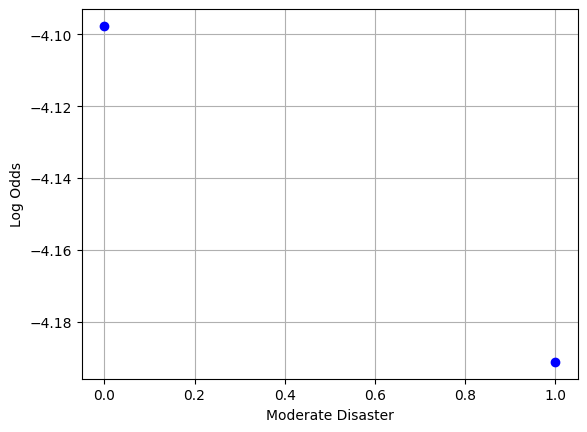

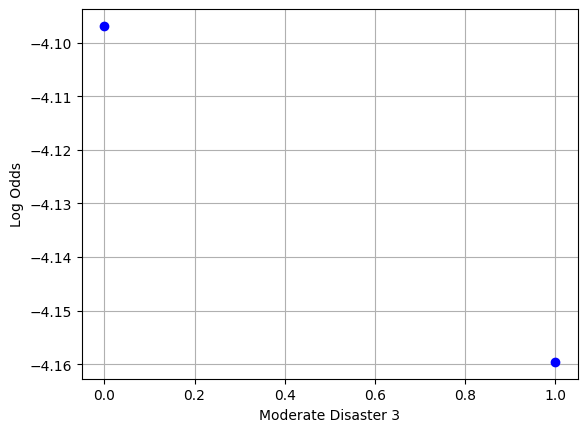

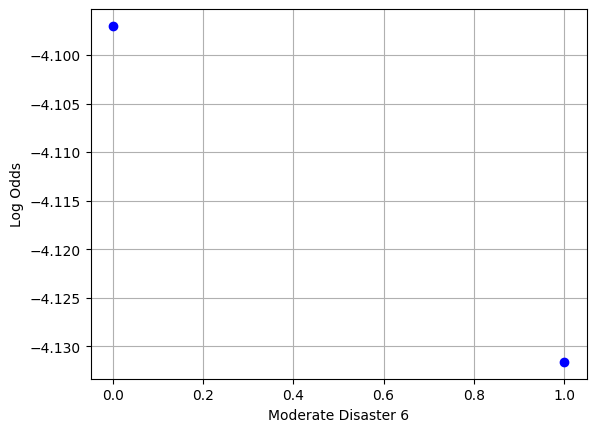

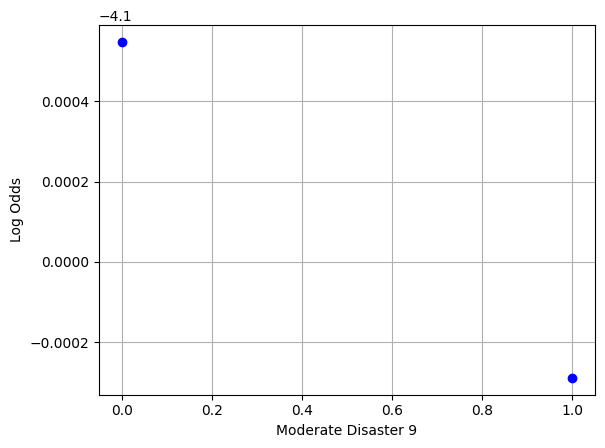

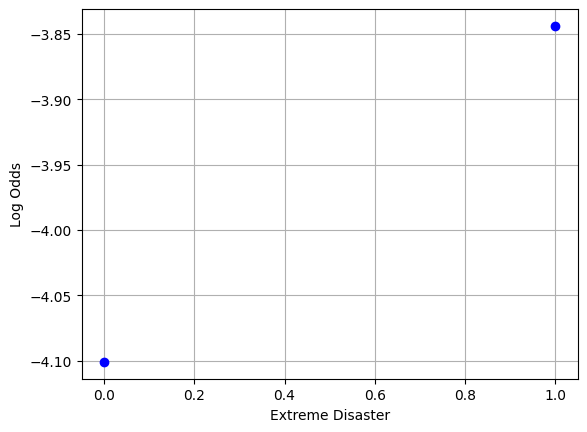

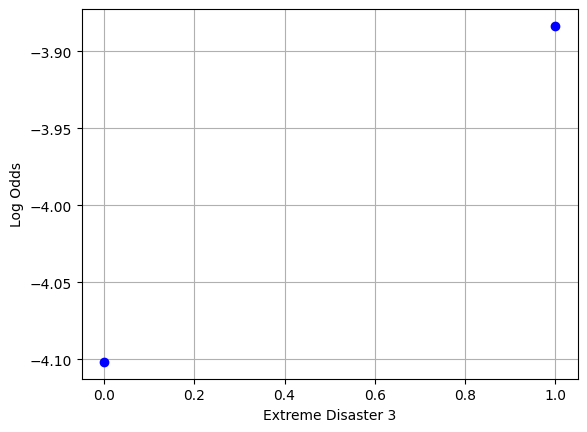

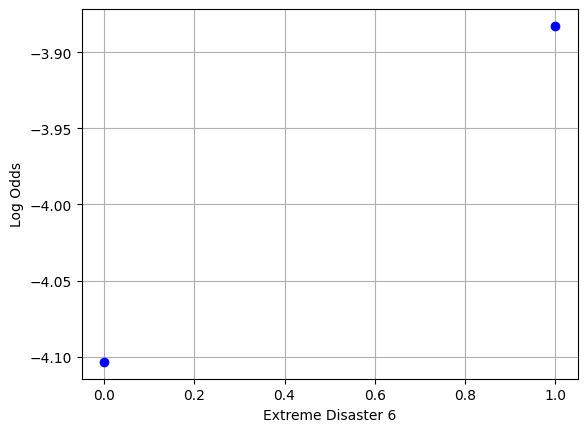

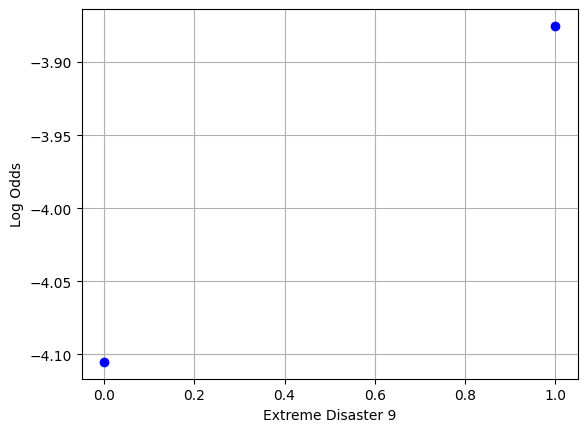

In [10]:
# Generally, it doesn't make sense to check log-odds linearity for binary columns
# However, we have several very similar columns that we need to remove due to multicollinearity
# We select the variables with the greatest separation (looking at y-axis)
binary_cols = ["Moderate Disaster","Moderate Disaster 3","Moderate Disaster 6","Moderate Disaster 9",
                 "Extreme Disaster","Extreme Disaster 3","Extreme Disaster 6","Extreme Disaster 9"]


for x in binary_cols:
    log_odds_plot(train,x)

# Although Moderate Disaster 9 has the smallest separation, the sign of the other variables makes even less sense
# as disasters are supposed to increase probability of default
# Interestingly, the highest separation for extreme disasters is the 1 month indicator.
# Meaning that if there isn't a default the next month, then we can ignore the fact that an extreme disaster happened
train.drop(columns=["Moderate Disaster","Moderate Disaster 3","Moderate Disaster 6",
                    "Extreme Disaster 3","Extreme Disaster 6","Extreme Disaster 9"],inplace=True)

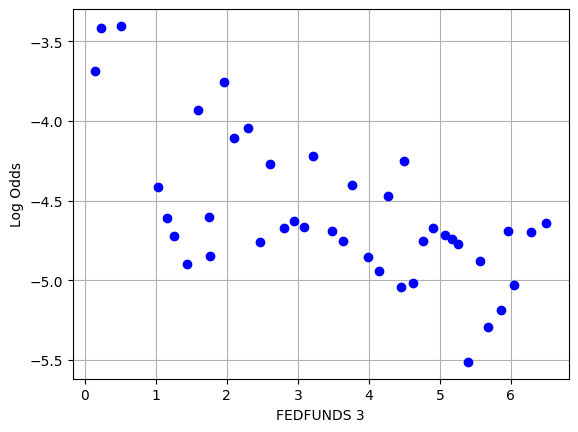

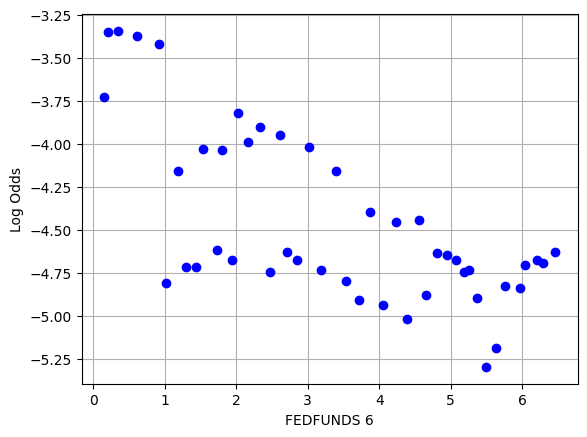

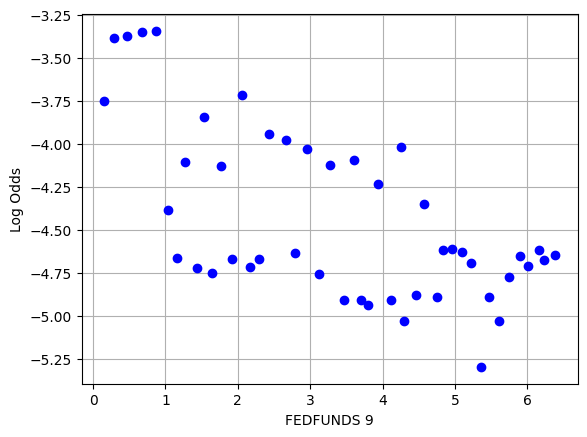

c:\Users\arnur\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


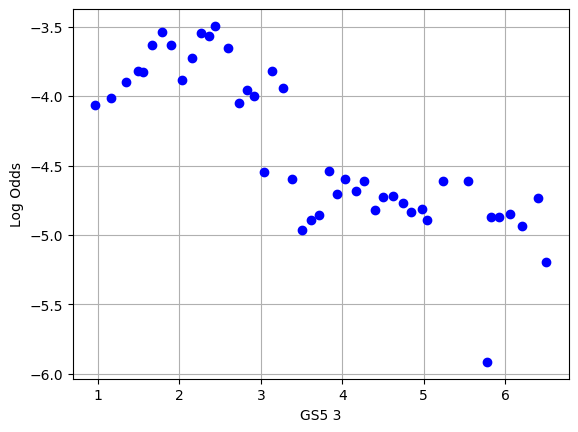

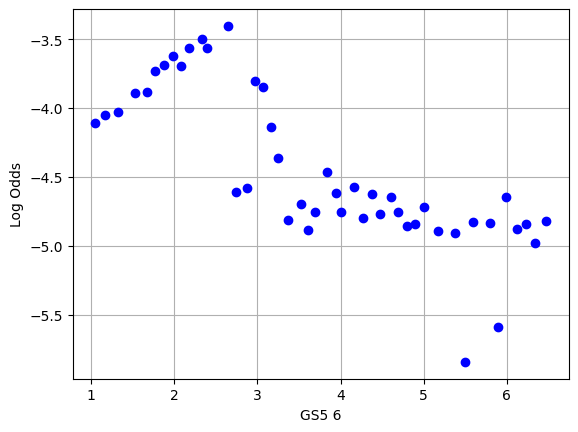

c:\Users\arnur\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


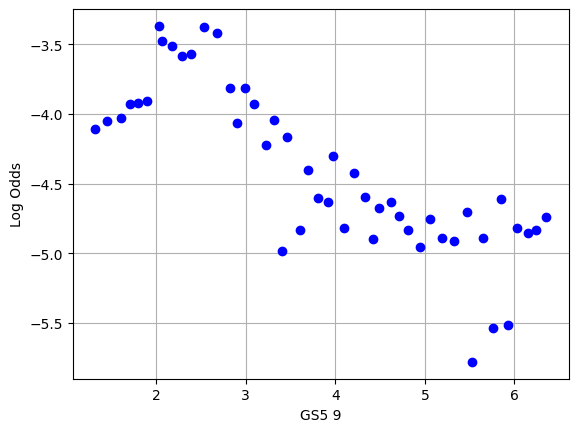

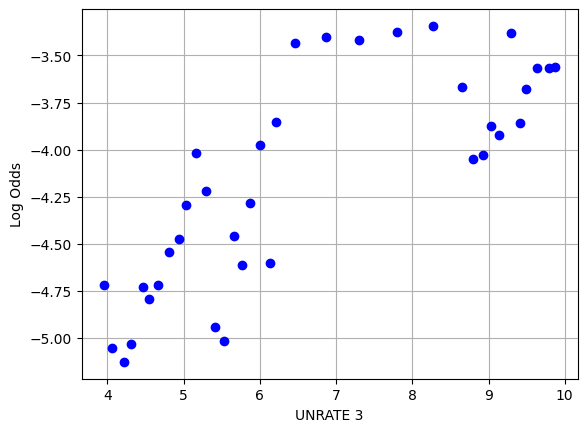

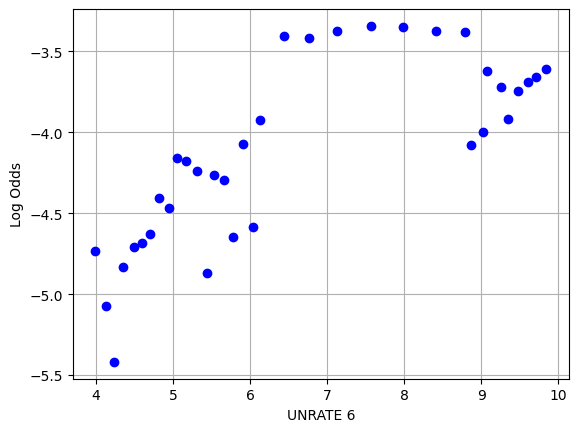

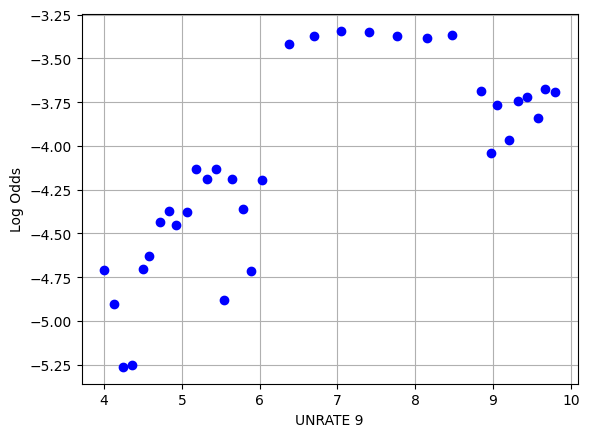

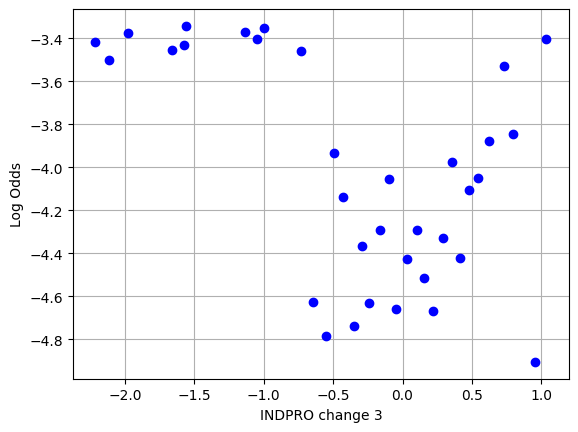

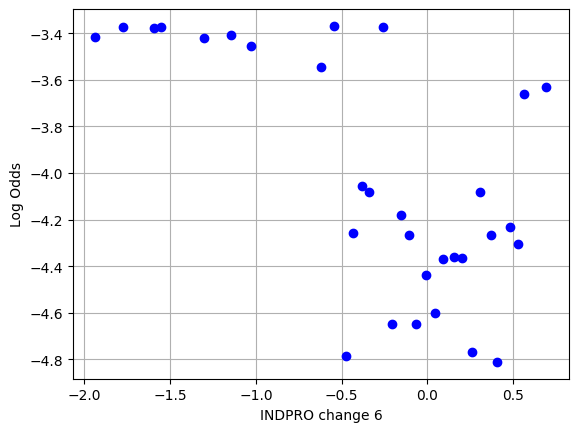

c:\Users\arnur\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


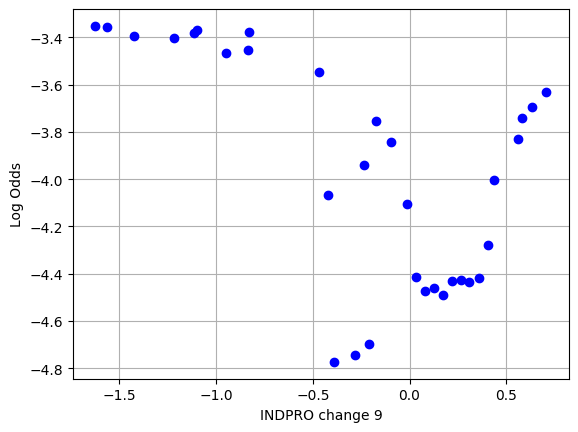

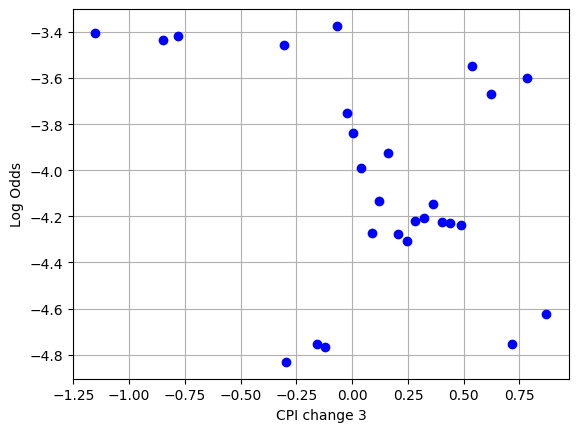

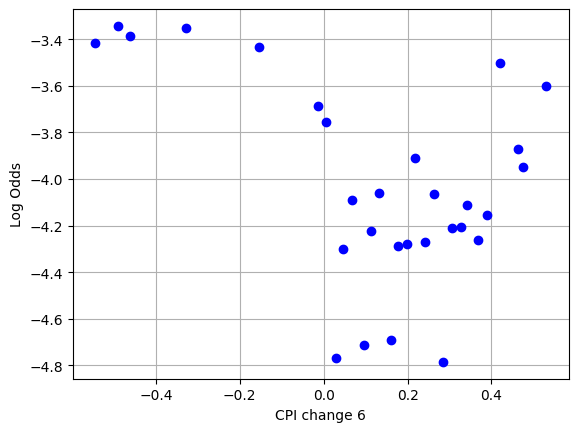

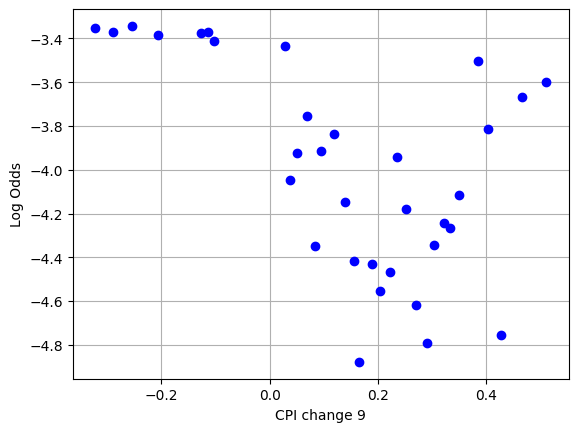

In [11]:
# For macro columns, we also have multicollinear columns that we want to remove
macro_cols = ["FEDFUNDS 3","FEDFUNDS 6","FEDFUNDS 9","GS5 3","GS5 6","GS5 9","UNRATE 3","UNRATE 6","UNRATE 9",
                "INDPRO change 3","INDPRO change 6","INDPRO change 9","CPI change 3","CPI change 6","CPI change 9"]

# These columns are much noisier than the mortgage-related columns, which can be explained by the fact that there are 
# 156 distinct macro observations from 1999-2011, so many of the bins may include only 1 or 2 observations.

# The bins having similar separation make it more difficult to determine which column is best.



for x in macro_cols:
    log_odds_plot(train,x)

# FEDFUNDS 3 is picked for its separation, GS5 9 because its graph looks the most linear with the correct sign,
# UNRATE 6 for its separation, INDPRO change 6 for the least non-linearity, CPI change 3 for the least non-linearity 
train.drop(columns=["FEDFUNDS 6","FEDFUNDS 9","GS5 3","GS5 6","UNRATE 3","UNRATE 9",
                "INDPRO change 3","INDPRO change 9","CPI change 6","CPI change 9"],inplace=True)


In [ ]:
# Finally, we deal with the fact that there is extreme class imbalance
print("Proportion of observations with default in next 12 months")
print(train["Default Next 12"].mean())

print("Proportion of loans that default")
print((train["Default Next 12"].sum()/12)/train["Loan Identifier"].unique().size)

print("Number of distinct loan defaults per year")
print((train["Default Next 12"].sum()/12) / 13)

print("Number of observations with default in next 12 months per month")
print((train["Default Next 12"].sum()/train["Period"].unique().size))

# For a 4-year training window, we have 400 distinct defaults to identify loan-varying coefficients,
# 1200 next-12-month defaults/ 100 distinct defaults to identify period-varying coefficients
# Due to our large dataset, even if we have a small proportion of defaults,
# we should be able to estimate probability of default at the already-existing variable values

# However, the problem appears when we need to extrapolate for unseen variable values
# A 4-year training window means only 48 distinct period-varying (macro) observations, 
# which is worsened by the fact that macro series are slow-moving and that we have taken over 3,6 or 9 months


# Over/under-sampling measures designed to deal with class imbalance cannot compensate for insufficient representative observations
# Hence, we solve the class imbalance only be varying the threshold for default prediction
# Extending the training window could resolve the relationship identification issue, 
# but too old observations may harm predictive capability during regime changes (non-stationarity)




Proportion of observations with default in next 12 months
0.016309909444656684
Proportion of loans that default
0.05112384895045511
Number of distinct loan defaults per year
98.7948717948718
Number of observations with default in next 12 months per month
99.43225806451613


In [22]:
# We now apply all our transformations based on our training set, to the whole dataset
data.drop(columns=["Real Wage change 3","Real Wage change 6","Real Wage change 9","Original Loan-to-Value (LTV)",
                   "Moderate Disaster","Moderate Disaster 3","Moderate Disaster 6","Extreme Disaster 3","Extreme Disaster 6",
                   "Extreme Disaster 9","FEDFUNDS 6","FEDFUNDS 9","GS5 3","GS5 6","UNRATE 3","UNRATE 9","INDPRO change 3",
                   "INDPRO change 9","CPI change 6","CPI change 9"],inplace=True)


data["Log Loan Age"] = data["Loan Age"].apply(lambda x: math.log(1 + x))


con = sqlite3.connect(database="data.sqlite")
(data
  .to_sql(name="final_data", 
          con=con, 
          if_exists="replace",
          index=False)
)
con.close()